# Homework 7 problem 1 <br>
Filippa Mudsam

**(c)**

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
rng = np.random.default_rng()
trapz = getattr(np, 'trapezoid', getattr(np, 'trapz', None))

x = np.array([-1.77, 2.47, 1.34, 2.18, 13.05, 1.60, 1.50, -1.97,
              0.79, 1.50, 2.00, 2.63, 1.19, -2.31, 0.87])
n = len(x)
logg = lambda a, b: n*b - np.sum(np.log(np.exp(2*b) + (x - a)**2))  

Start the chain at (0, 0) and run T = 5 × 104 steps for s = 0.02, 0.5, 5. Report the acceptance rates and the integrated autocorrelation time of α, and plot the first 400 values of α for each s.

In [3]:
T = int(5e4)
s_vals = [0.02, 0.5, 5]
chains_a = []    #alpha 
chains_b = []   #b = log(beta) 

for s in s_vals:
    a = np.zeros(T+1)   #start at (0, 0)
    b = np.zeros(T+1)
    acc = 0
    for t in range(T):
        ya = a[t] + s*rng.standard_normal()   # proposal sample
        yb = b[t] + s*rng.standard_normal()
        if np.log(rng.random()) < min(0, logg(ya, yb) - logg(a[t], b[t])):
            a[t+1] = ya
            b[t+1] = yb
            acc += 1    #accept
        else:
            a[t+1] = a[t]
            b[t+1] = b[t]
    chains_a.append(a)
    chains_b.append(b)

In [4]:
# integrated correlation formula 1 + 2*sum k>= 1 (rho(k))

tau = np.zeros(len(s_vals))
for j in range(len(s_vals)):
    a = chains_a[j]
    d = a - np.mean(a)
    tau[j] = 1
    k = 1
    while k < len(a)/2:
        rho = np.sum(d[:-k]*d[k:])/np.sum(d**2)
        if rho < 0:
            break
        tau[j] = tau[j] + 2*rho
        k += 1
    print('s = %5.2f:  integrated autocorrelation time of alpha = %.1f' % (s_vals[j], tau[j]))

s =  0.02:  integrated autocorrelation time of alpha = 722.6
s =  0.50:  integrated autocorrelation time of alpha = 8.6
s =  5.00:  integrated autocorrelation time of alpha = 212.2


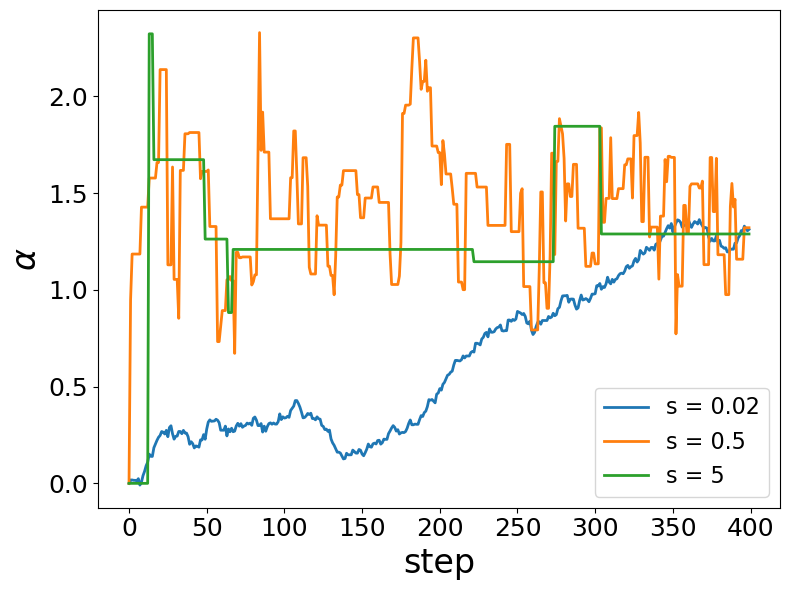

In [5]:
plt.figure(1, figsize=(8, 6))
for j in range(len(s_vals)):
    plt.plot(chains_a[j][:400], linewidth=2, label='s = %g' % s_vals[j]) 
plt.legend(fontsize=16)
plt.tick_params(labelsize=18)
plt.xlabel('step', fontsize=24)
plt.ylabel('$\\alpha$', fontsize=24)
plt.tight_layout()
plt.show()


For the best s, discard the first 5000 steps, plot the samples of (α, log β) over contours of the exact posterior computed on a grid, and report the posterior mean and 90% interval of α and of β from both the chain and the grid.

best s = 0.5


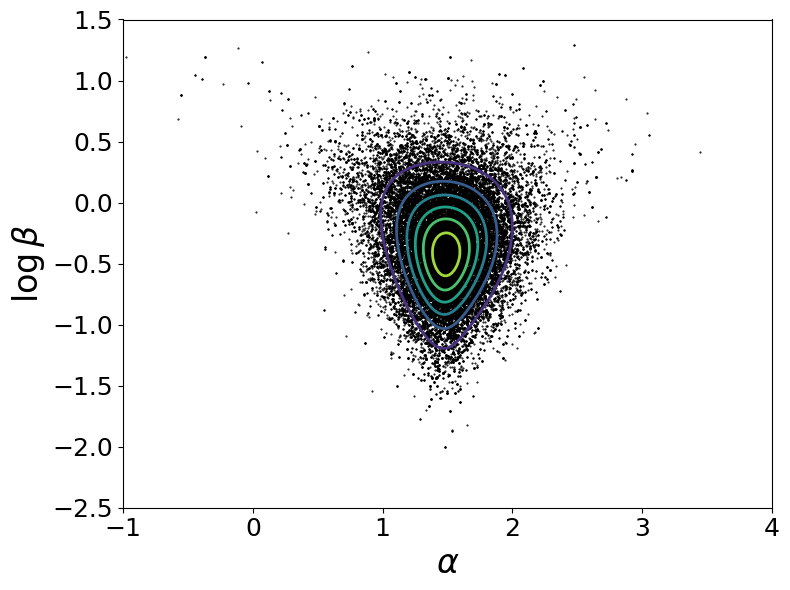

In [6]:
best = np.argmin(tau)
print('best s =', s_vals[best])

burn = 5000 #get rid fo first 5000
a_s = chains_a[best][burn+1:]
b_s = chains_b[best][burn+1:]

#exact posterior of (alpha, b) 
a_grid = np.linspace(-3, 5, 400)
b_grid = np.linspace(-3, 3, 400)
G = np.zeros((len(b_grid), len(a_grid)))  
for i in range(len(b_grid)):
    for j in range(len(a_grid)):
        G[i, j] = logg(a_grid[j], b_grid[i])
G = np.exp(G - np.max(G))                 

plt.figure(2, figsize=(8, 6))
plt.plot(a_s, b_s, 'k.', markersize=1)
plt.contour(a_grid, b_grid, G, 8, linewidths=2)
plt.xlim([-1, 4])
plt.ylim([-2.5, 1.5])
plt.tick_params(labelsize=18)
plt.xlabel('$\\alpha$', fontsize=24)
plt.ylabel('$\\log \\beta$', fontsize=24)
plt.tight_layout()
plt.show()

report the posterior mean and 90% interval of α and of β from both the chain and the grid. 

In [7]:
#chain
beta_s = np.exp(b_s)
print('chain:  alpha mean = %.3f   90%% interval = [%.3f, %.3f]'
      % (np.mean(a_s), np.percentile(a_s, 5), np.percentile(a_s, 95)))
print('chain:  beta  mean = %.3f   90%% interval = [%.3f, %.3f]'
      % (np.mean(beta_s), np.percentile(beta_s, 5), np.percentile(beta_s, 95)))

# grid 
marg_a = trapz(G, b_grid, axis=0)          
marg_a = marg_a/trapz(marg_a, a_grid)
marg_b = trapz(G, a_grid, axis=1)         
marg_b = marg_b/trapz(marg_b, b_grid)

cdf_a = np.cumsum(marg_a)*(a_grid[1] - a_grid[0])
cdf_b = np.cumsum(marg_b)*(b_grid[1] - b_grid[0])

print('grid:   alpha mean = %.3f   90%% interval = [%.3f, %.3f]'
      % (trapz(a_grid*marg_a, a_grid),
         np.interp(0.05, cdf_a, a_grid), np.interp(0.95, cdf_a, a_grid)))
print('grid:   beta  mean = %.3f   90%% interval = [%.3f, %.3f]'
      % (trapz(np.exp(b_grid)*marg_b, b_grid),
         np.exp(np.interp(0.05, cdf_b, b_grid)), np.exp(np.interp(0.95, cdf_b, b_grid))))

chain:  alpha mean = 1.480   90% interval = [1.017, 1.932]
chain:  beta  mean = 0.787   90% interval = [0.378, 1.415]
grid:   alpha mean = 1.483   90% interval = [1.020, 1.923]
grid:   beta  mean = 0.776   90% interval = [0.371, 1.372]


Compare with the sample mean and sample median of the xi. Why do s = 0.02 and s = 5 both do badly, in opposite ways?

In [8]:
print('sample mean of x   =', np.mean(x))
print('sample median of x =', np.median(x))

sample mean of x   = 1.6713333333333333
sample median of x = 1.5


The sample mean is a little bit larger than the sample median alluding to a right skew, which would influence the differece. s = 0.02 is too small of a step while s = 5 is way too big. 

**(d)**

Draw 2000 data sets of n = 10, 100, 1000 flashes from (α, β) = (1.5, 0.8) and compute the sample mean and the sample median of each. For each estimator and each n you then have 2000 estimates. Measure how widely they scatter by the interquartile range (IQR), the distance between their 25th and 75th percentiles, divided by 1.349; for normally distributed estimates this equals the standard deviation. We use it because the standard deviation of a Cauchy sample mean is not defined. Report this scatter for each estimator and each n. Which estimator improves with n?

In [9]:
alpha_true = 1.5
beta_true = 0.8
Ndata = 2000

for n_flash in [10, 100, 1000, 10000]:
    U = rng.random((Ndata, n_flash))
    X = alpha_true + beta_true*np.tan(np.pi*(U - 0.5))   

    means = np.mean(X, axis=1)
    medians = np.median(X, axis=1)

    scatter_mean = (np.percentile(means, 75) - np.percentile(means, 25))/1.349
    scatter_median = (np.percentile(medians, 75) - np.percentile(medians, 25))/1.349
    print('n = %4d:  scatter of mean = %.3f   scatter of median = %.3f'
          % (n_flash, scatter_mean, scatter_median))

n =   10:  scatter of mean = 1.205   scatter of median = 0.394
n =  100:  scatter of mean = 1.185   scatter of median = 0.126
n = 1000:  scatter of mean = 1.190   scatter of median = 0.039
n = 10000:  scatter of mean = 1.222   scatter of median = 0.012


The sample median gets better as n gets larger. the sample mean does not settle as n gets large. The law of large numbers needs the expectation to be a finite value, but the cauchy distribution does not have this.